## Импортируем данные

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 7.1 MB/s eta 0:00:00


In [ ]:
!pip install CatBoost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from catboost import CatBoostRegressor

##EDA

In [ ]:
df = pd.read_csv('data_2018.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56318 entries, 0 to 56317
Data columns (total 70 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              56318 non-null  int64  
 1   loan_amnt                       56318 non-null  float64
 2   term                            56318 non-null  int64  
 3   emp_length                      51384 non-null  float64
 4   home_ownership                  56318 non-null  object 
 5   annual_inc                      56318 non-null  float64
 6   verification_status             56318 non-null  object 
 7   purpose                         56318 non-null  object 
 8   addr_state                      56318 non-null  object 
 9   application_type                56318 non-null  object 
 10  dti                             56167 non-null  float64
 11  delinq_2yrs                     56318 non-null  float64
 12  inq_last_6mths                  

In [ ]:
df['num_tl_120dpd_2m'].unique()

array([ 0., nan])

Признаки grade, sub_grade и installment исключаем из регрессии. grade и sub_grade - это кредитный рейтинг, по которому платформа напрямую назначает ставку, то есть фактически та же ставка, записанная другими словами. installment (ежемесячный платёж) рассчитывается из ставки, суммы и срока по формуле аннуитета, поэтому модель смогла бы восстановить ставку обратно из платежа. Все три известны только потому, что ставка уже назначена, поэтому эти признаки мы полностью убираем

In [ ]:
df['месяц'] = pd.to_datetime(df['issue_d']).dt.month
df.groupby('месяц')['int_rate'].mean()

/tmp/ipykernel_8028/3437692064.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['месяц'] = pd.to_datetime(df['issue_d']).dt.month


,int_rate
месяц,
1,13.116585
2,13.219036
3,13.189950
4,13.295999
5,13.278470
6,13.300617
7,14.017121
8,14.102494
9,13.810483


Диапозон ставки колеблется между 13.1% - 14.1%, поэтому этот признак малоинформативен для нашей модели и мы его убираем

## Распределение целевой переменной

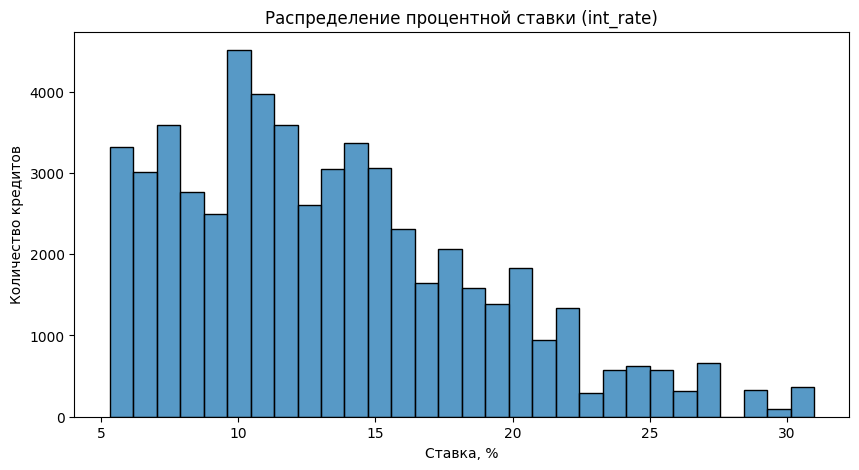

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['int_rate'], bins=30, color='lightblue')
plt.title('Распределение процентной ставки (int_rate)')
plt.xlabel('Ставка, %')
plt.ylabel('Количество кредитов')
plt.show()

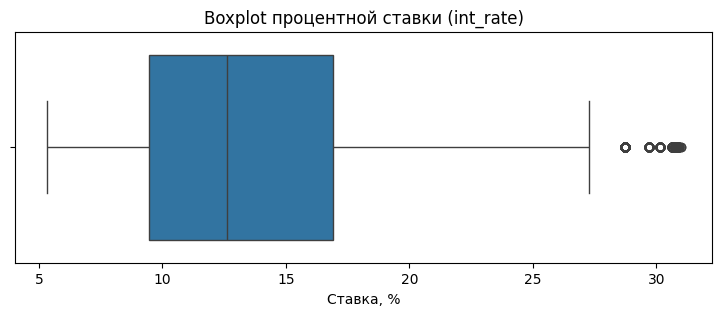

In [ ]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=df['int_rate'], color='lightblue')
plt.title('Boxplot процентной ставки (int_rate)')
plt.xlabel('Ставка, %')
plt.show()

Основная масса ставок лежит в диапазоне 9,5–17% (медиана 12,5%). Распределение умеренно скошено вправо: есть длинный хвост и единичные высокие ставки до 32%. Эти выбросы - не ошибки, а реальные дорогие кредиты для рискованных заёмщиков, поэтому мы их сохраняем. Скошенность учтём при моделировании: сравним модель на исходной и логарифмированной ставке и будем оценивать качество по MAE и RMSE.

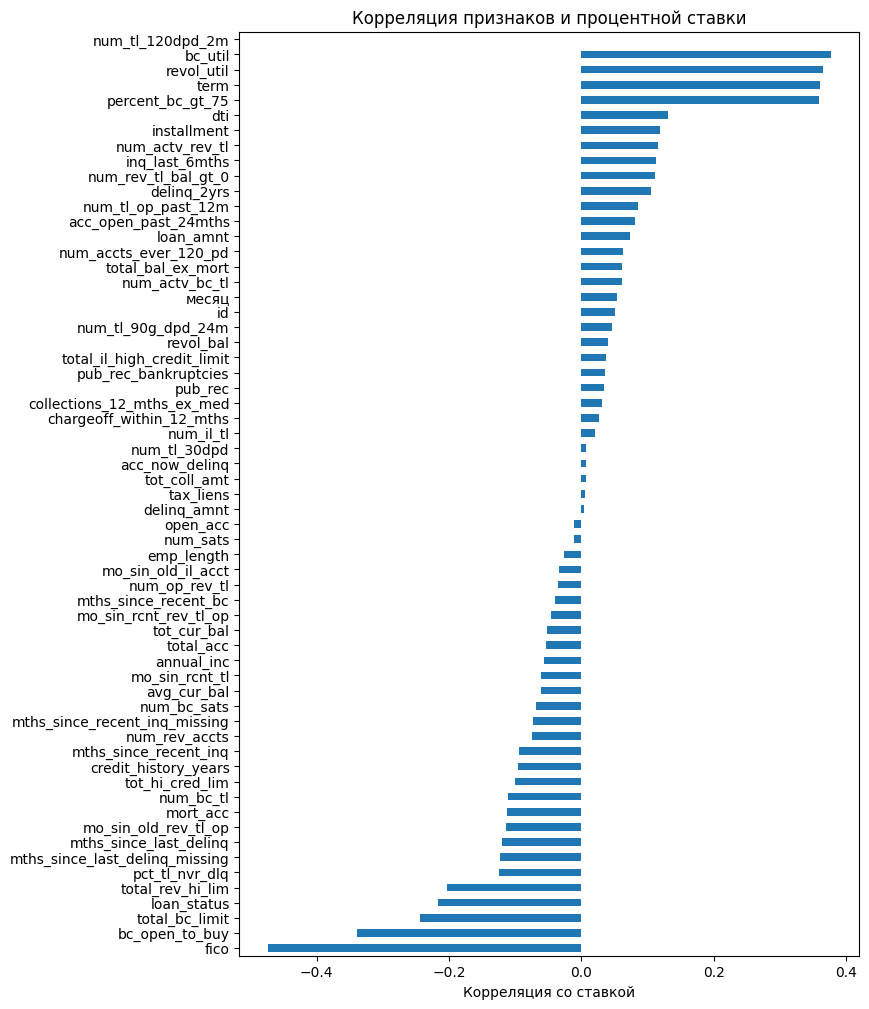

In [ ]:
corr = df.corr(numeric_only=True)['int_rate'].drop('int_rate')
corr = corr.sort_values()

plt.figure(figsize=(8, 12))
corr.plot(kind='barh', color='lightblue')
plt.title('Корреляция признаков и процентной ставки')
plt.xlabel('Корреляция со ставкой')
plt.show()

Сильнее всего на ставку влияет fico (кредитный скоринг заёмщика): чем выше скоринг, тем ниже ставка

Прямая связь (больше долгов, выше ставка): bc_util (использование лимита по картам, %), revol_util (использование возобновляемого лимита, %), percent_bc_gt_75 (доля карт, загруженных более чем на 75%). Чем сильнее человек выбрал свои лимиты, тем выше ставка.

Обратная связь (больше надёжности, ниже ставка): bc_open_to_buy (свободный остаток лимита по картам), total_bc_limit (суммарный лимит по картам), total_rev_hi_lim (суммарный лимит по возобновляемым кредитам), pct_tl_nvr_dlq (доля счетов без единой просрочки). Большие лимиты и отсутствие просрочек - признаки надёжного заёмщика, поэтому ставка ниже

Также заметно влияет term (срок кредита): чем длиннее срок, тем выше ставка. Большинство остальных признаков связаны со ставкой слабо.

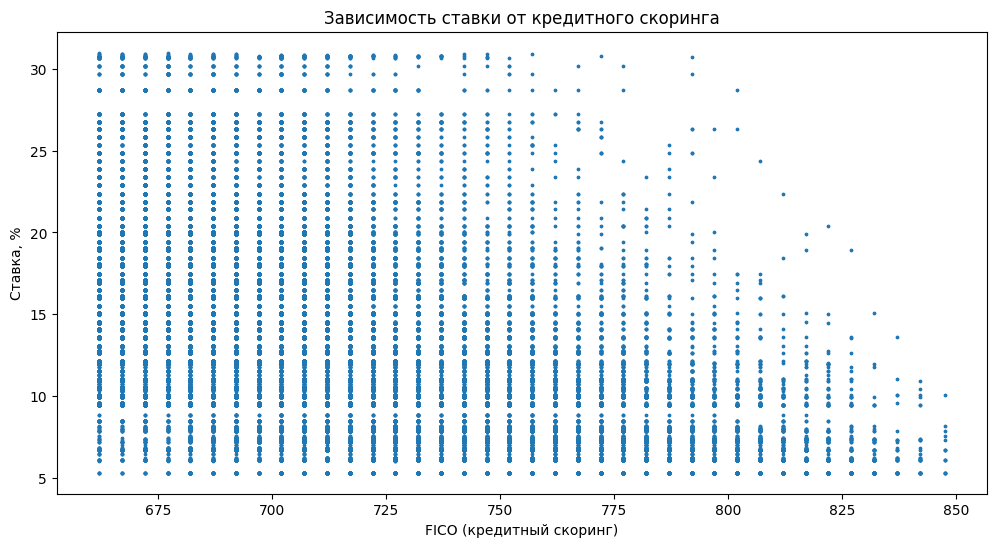

In [ ]:
plt.figure(figsize=(12, 6))
plt.scatter(df['fico'], df['int_rate'], s=3, color='lightblue')
plt.title('Зависимость ставки от кредитного скоринга')
plt.xlabel('FICO (кредитный скоринг)')
plt.ylabel('Ставка, %')
plt.show()

На графике видны два эффекта. Во-первых, ставка не превышает 31% - это не особенность выборки, а правило платформы LendingClub: кредиты дороже этого порога не выдаются (ограничения законодательства). Из-за этого сверху образуется плато. После FICO 760 график начинает клониться вниз, это более надежные клиенты, которым кредиты выдаются дешевле. Также люди с FICO ниже 662 даже не допускались в базу данных, поскольку это максимально ненадежные люди, которые могут не вернуть кредит. Значение FICO 850 это потолок самой шкалы.

/tmp/ipykernel_8028/3520782205.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg = df.groupby('util_groups')['int_rate'].mean()


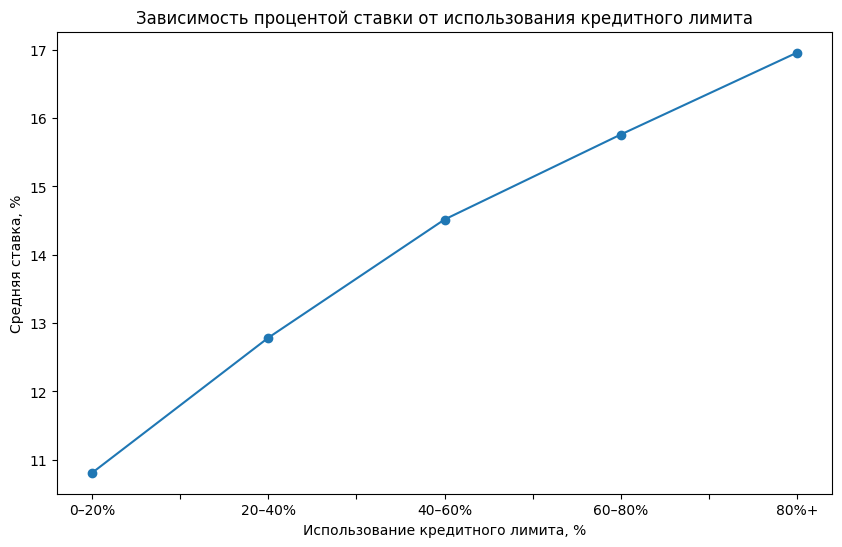

In [ ]:
bins = [0, 20, 40, 60, 80, np.inf]
labels = ['0–20%', '20–40%', '40–60%', '60–80%', '80%+']
df['util_groups'] = pd.cut(df['revol_util'], bins=bins, labels=labels)
avg = df.groupby('util_groups')['int_rate'].mean()

avg.plot(kind='line', marker='o', figsize=(10, 6), color='lightgreen')
plt.xlabel('Использование кредитного лимита, %')
plt.ylabel('Средняя ставка, %')
plt.title('Зависимость процентой ставки от использования кредитного лимита')
plt.show()

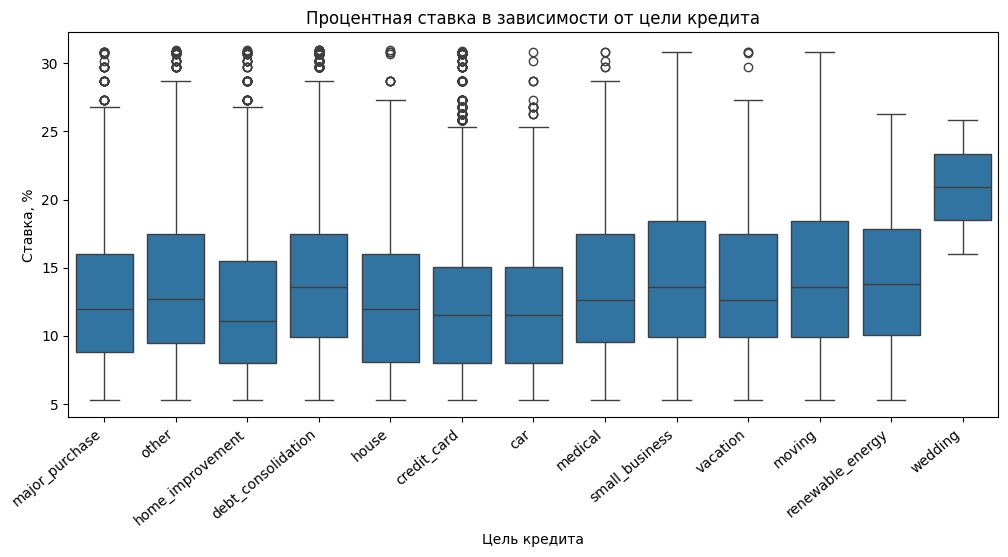

In [ ]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='purpose', y='int_rate', color='lightblue')
plt.xlabel('Цель кредита')
plt.ylabel('Ставка, %')
plt.xticks(rotation=40, ha='right')
plt.title('Процентная ставка в зависимости от цели кредита')
plt.show()

Ставка зависит от цели: дороже всего кредиты на свадьбу, дешевле - на авто и рефинансирование карт

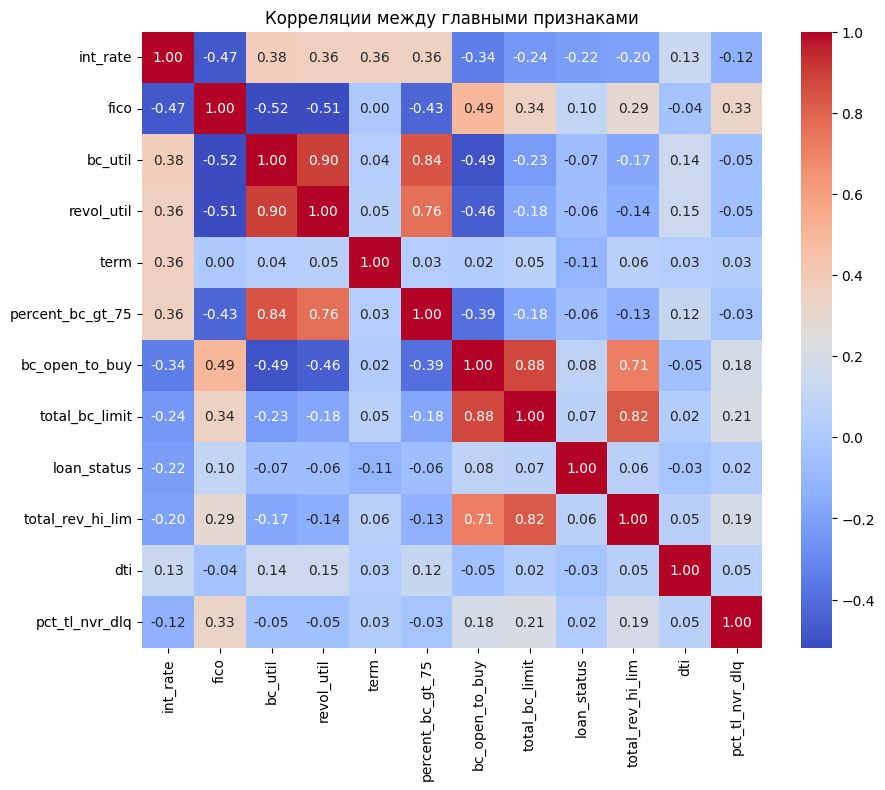

In [ ]:
top = df.corr(numeric_only=True)['int_rate'].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляции между главными признаками')
plt.show()

Есть признаки, несущие почти одну информацию:

bc_util и revol_util (0,90)

bc_open_to_buy и total_bc_limit (0,88)

percent_bc_gt_75 и bc_util (0,84)

total_bc_limit и total_rev_hi_lim (0,82)

total_rev_hi_lim и bc_open_to_buy (0,71)

Это мультиколлинеарность. Из каждой пары стоит оставить один признак, либо применить Ridge-regression/PCA

/tmp/ipykernel_8028/4075665207.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table = df.pivot_table(index='fico_group', columns='term', values='int_rate', aggfunc='mean')


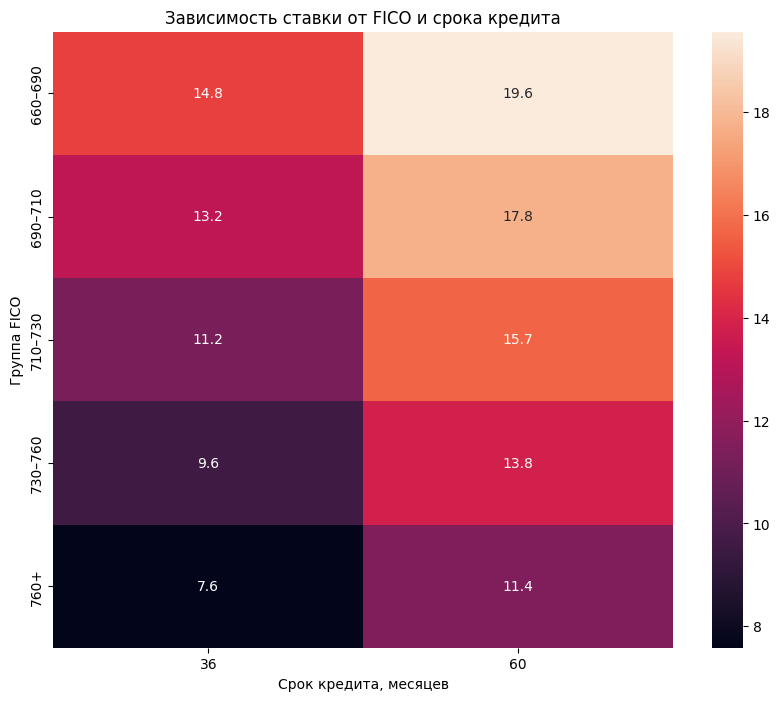

In [ ]:
df['fico_group'] = pd.cut(df['fico'], bins=[660, 690, 710, 730, 760, 850], labels=['660–690', '690–710', '710–730', '730–760', '760+'])
table = df.pivot_table(index='fico_group', columns='term', values='int_rate', aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(table, annot=True, fmt='.1f')
plt.xlabel('Срок кредита, месяцев')
plt.ylabel('Группа FICO')
plt.title('Зависимость ставки от FICO и срока кредита')
plt.show()

Ставка зависит одновременно от FICO и срока кредита. Платформа предлагает только два срока - 36 и 60 месяцев. Самые дешёвые кредиты у заёмщиков с высоким скорингом на короткий срок, а самые дорогие - у заёмщиков с низким скорингом на 60 месяцев. Оба фактора действуют в одну сторону: и низкий скоринг, и длинный срок повышают ставку.

##Выделяем целевую переменную и датасет для обучения (удаляем лишние столбцы)

In [ ]:
delete = [
    'grade', 'sub_grade', 'installment',
    'loan_status',
    'id',
    'util_groups', 'fico_group',
    'issue_d', 'issue_d_dt',
    'num_tl_120dpd_2m']

df = df.drop(columns=delete)
df.head(5)

,loan_amnt,term,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,application_type,dti,...,num_rev_tl_bal_gt_0,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,int_rate,fico,credit_history_years,mths_since_last_delinq_missing,mths_since_recent_inq_missing,месяц
0,3000.0,36,9.0,RENT,52000.0,Source Verified,major_purchase,WA,Individual,0.58,...,1.0,0.0,0.0,1.0,7.34,762.0,20.2,0,0,3
1,5000.0,36,10.0,OWN,55000.0,Not Verified,other,GA,Individual,14.18,...,3.0,0.0,0.0,2.0,11.98,677.0,16.6,0,0,3
2,7000.0,36,0.0,MORTGAGE,40000.0,Verified,home_improvement,TX,Individual,20.25,...,2.0,0.0,0.0,2.0,11.98,697.0,11.0,0,0,3
3,30000.0,36,10.0,OWN,57000.0,Verified,debt_consolidation,FL,Individual,27.58,...,4.0,0.0,0.0,5.0,21.85,682.0,17.9,0,0,3
4,21000.0,60,10.0,OWN,85000.0,Source Verified,house,NY,Individual,15.76,...,7.0,0.0,0.0,4.0,20.39,667.0,9.3,0,0,3


In [ ]:
nones = df.isna().sum()
nones[nones > 0].sort_values(ascending = False)

,0
mths_since_last_delinq,31114
emp_length,4934
mths_since_recent_inq,4701
mo_sin_old_il_acct,1869
bc_util,999
percent_bc_gt_75,958
bc_open_to_buy,957
mths_since_recent_bc,887
dti,151
revol_util,74


Остановимся на признаках с амым большим кол-вом нанов для которых замена медианой не подойдет
Пропуски в признаке mths_since_last_delinq заполним максимальным значением + 1. Этот признак отвечает за время, прошедшее с последней просрочки кредита. Чем больше значение в нем, тем значит человек надежней, тем ниже его ставка. None значения в этом признаке означают, что у человека вообще не было просрочек.
С признаком mths_since_recent_inq поступим также. Его значения это количество месяцев, прошедших с момента последнего официального запроса вашей кредитной истории. Давно запрашивали кред. историю - скорее всего, у человека финансовое положение стаильное, недавно запрашивали и опять пришел за кредитом - возможно финансовые трудности. None - если ни разу не запрашивалась кред. история.

# Замена None с помощью SimpleImputer

In [ ]:
df.isna().sum().sum()

np.int64(0)

# Разбиваем На X и y

In [ ]:
X = df.drop(columns=['int_rate'])
y = df['int_rate']

##Кодируем категориальные признаки

In [ ]:
X = pd.get_dummies(X)

##Разделение на выборки

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)

##Заполнение пропусков

In [ ]:
for col in ['mths_since_last_delinq', 'mths_since_recent_inq']:
    maxim = X_train[col].max()
    X_train[col] = X_train[col].fillna(maxim)
    X_test[col] = X_test[col].fillna(maxim)

med = X_train.median(numeric_only=True)
X_train = X_train.fillna(med)
X_test = X_test.fillna(med)

##Масштабируем

In [ ]:
scaler = StandardScaler()
X_train_mash = scaler.fit_transform(X_train)
X_test_mash = scaler.transform(X_test)

# KNN

In [ ]:
def objective_knn(trial):
    params = {'n_neighbors': trial.suggest_int('n_neighbors', 2, 64)}
    knn = KNeighborsRegressor(**params, weights='distance')
    scores = cross_val_score(knn, X_train_mash, y_train, cv=3, scoring='neg_mean_absolute_error')
    mae = scores.mean()
    return mae

In [ ]:
study_knn = optuna.create_study(direction='maximize')
study_knn.optimize(objective_knn, n_trials=30)
print('Лучшее значение MAE на кросс-валидации', study_knn.best_value)
print('Лучшие параметры', study_knn.best_params)

In [ ]:
best_knn = KNeighborsRegressor(**study_knn.best_params, weights='distance')
best_knn.fit(X_train_mash, y_train)
pred_knn = best_knn.predict(X_test_mash)
print("kNN:")
print("MAE:", mean_absolute_error(y_test, pred_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_knn)))
print("R2:", r2_score(y_test, pred_knn))

#Линейная регрессия

In [ ]:
def objective_lr(trial):
    params = {'alpha': trial.suggest_float('alpha', 0.001, 10),
              'l1_ratio': trial.suggest_float('l1_ratio', 0, 1)}
    lr = ElasticNet(**params)
    rmse_scores = cross_val_score(lr,X_train_mash, y_train, cv=3, scoring='neg_mean_absolute_error')
    mae = rmse_scores.mean()
    return mae

In [ ]:
study_lr = optuna.create_study(direction="maximize")
study_lr.optimize(objective_lr, n_trials=30)

print('Лучшее значение MAE на кросс-валидации', study_lr.best_value)
print('Лучшие параметры', study_lr.best_params)

In [ ]:
best_elastic = ElasticNet(**study_lr.best_params, random_state=67)
best_elastic.fit(X_train_mash, y_train)
pred = best_elastic.predict(X_test_mash)

mae_lr = mean_absolute_error(y_test, pred)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred))
r2_lr = r2_score(y_test, pred)

print("Линейная регрессия:")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2:", r2_lr)

NameError: name 'study_lr' is not defined

# Решающее дерево

In [ ]:
def objective_tr(trial):
    params = {'max_depth': trial.suggest_int('max_depth', 3, 15),
              'min_samples_split': trial.suggest_int('min_samples_split', 2, 30),
              'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
              'random_state': 67}
    tree = DecisionTreeRegressor(**params)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring='neg_mean_absolute_error')
    mae = scores.mean()
    return mae

In [ ]:
study_tr = optuna.create_study(direction='maximize')
study_tr.optimize(objective_tr, n_trials=30)

print('Лучшее значение MAE на кросс-валидации', study_tr.best_value)
print('Лучшие параметры', study_tr.best_params)

In [ ]:
best_params_tr = study_tr.best_params
best_tr = DecisionTreeRegressor(**best_params_tr, random_state=67)
best_tr.fit(X_train, y_train)
pred_tr = best_tr.predict(X_test)
print("Решающее дерево:")
print("MAE:", mean_absolute_error(y_test, pred_tr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_tr)))
print("R2:", r2_score(y_test, pred_tr))

# Случайный лес

In [ ]:
def objective_rf(trial):
    param = {'n_estimators': trial.suggest_int('n_estimators', 50, 300),
             'max_depth': trial.suggest_int('max_depth', 3, 25),
             'min_samples_split': trial.suggest_int('min_samples_split', 2, 30),
             'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
             'random_state': 55}
    rf = RandomForestRegressor(**param)
    rmse_scores = cross_val_score(rf, X_train, y_train, cv=3, scoring='neg_mean_absolute_error')
    mae = rmse_scores.mean()
    return mae

In [ ]:
study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=5) #проверяли на 15, после 5 итерации уменьшаться практически перестает ошибка

print('Лучшее значение MAE на кросс-валидации:')
print(study_rf.best_value)

print('Лучшие параметры:')
print(study_rf.best_params)

[I 2026-06-16 20:38:54,093] A new study created in memory with name: no-name-6302c42e-5d46-4fa3-9002-48c113ec8e90
[I 2026-06-16 20:44:43,816] Trial 0 finished with value: 3.0065965212580674 and parameters: {'n_estimators': 150, 'max_depth': 11, 'min_samples_split': 9, 'min_samples_leaf': 20}. Best is trial 0 with value: 3.0065965212580674.
[I 2026-06-16 20:46:43,132] Trial 1 finished with value: 3.3099614188823523 and parameters: {'n_estimators': 117, 'max_depth': 4, 'min_samples_split': 21, 'min_samples_leaf': 16}. Best is trial 0 with value: 3.0065965212580674.
[I 2026-06-16 21:00:11,023] Trial 2 finished with value: 2.966934142293392 and parameters: {'n_estimators': 279, 'max_depth': 17, 'min_samples_split': 30, 'min_samples_leaf': 4}. Best is trial 2 with value: 2.966934142293392.
[I 2026-06-16 21:06:38,817] Trial 3 finished with value: 3.0182866654027216 and parameters: {'n_estimators': 184, 'max_depth': 10, 'min_samples_split': 13, 'min_samples_leaf': 5}. Best is trial 2 with val

In [ ]:
best_params = study_rf.best_params
best_rf = RandomForestRegressor(**best_params, random_state=55)

best_rf.fit(X_train, y_train)
pred = best_rf.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print('Random Forest:')
print('MAE:', mae)
print('RMSE:', rmse)
print('R2:', r2)

# Boosting Catboost

https://github.com/vgorbatikov/ml-titanic/blob/main/spaceship-titanic.ipynb - откуда брали бустинг + optuna

In [ ]:
def objective_cat(trial):
    param = {
        'iterations': trial.suggest_int('iterations', 500, 2000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 20), # параметр рег.
        'loss_function': 'RMSE',
        'random_seed': 55,
    }
    estimator = CatBoostRegressor(**param, verbose=False) #** перед param это распаковка словаря для передачи в параметры, verbose за логи отвечает, фолс значит без них
    rmse_score = cross_val_score(estimator, X_train, y_train, cv=3, scoring='neg_root_mean_squared_error').mean() #нег значит минус рмсе
    return rmse_score

In [ ]:
study_cat = optuna.create_study(direction='maximize') # максимизируем отрицательные рмсе
study_cat.optimize(objective_cat, n_trials=5)

print(f'лучшее value {study_cat.best_value}')
print(f'лучшие параметры {study_cat.best_params}')

In [ ]:
best_params = study_cat.best_params
catboost_model = CatBoostRegressor(**best_params,random_seed=55,verbose=False)
catboost_model.fit(X_train, y_train)
pred_cat = catboost_model.predict(X_test)

print("CatBoost:")
print("MAE:", mean_absolute_error(y_test, pred_cat))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_cat)))
print("R2:", r2_score(y_test, pred_cat))

##Важность признаков

In [ ]:
y_pred_train = catboost_model.predict(X_train)
y_pred_test = catboost_model.predict(X_test)

print(f'MAE train {mean_absolute_error(y_train, y_pred_train)}')
print(f'MAE test {mean_absolute_error(y_test, y_pred_test)}')
print(f'RMSE train {mean_squared_error(y_train, y_pred_train) ** 0.5}')
print(f'RMSE test{mean_squared_error(y_test, y_pred_test) ** 0.5}')
print(f'r2 train {r2_score(y_train, y_pred_train)}')
print(f'r2 test {r2_score(y_test, y_pred_test)}')

https://vk.com/@karpovcourses-interpretaciya-modelei-mashinnogo-obucheniya-v-python-shap

In [ ]:
shap.initjs()

In [ ]:
explainer = shap.TreeExplainer(catboost_model)
explainer = shap.TreeExplainer(catboost_model)
shap_values = explainer.shap_values(X_train)

In [ ]:
shap.summary_plot(shap_values, X_train, plot_type='bar', plot_size=(10,6))

##Сравнительный анализ

In [ ]:
preds = {"ElasticNet":    best_elastic.predict(X_test_mash),
         "kNN":           best_knn.predict(X_test_mash),
         "Decision Tree": best_tr.predict(X_test),
         "Random Forest": best_rf.predict(X_test),
         "CatBoost":      catboost_model.predict(X_test),}

rows = []
for name, p in preds.items():
    rows.append([name,
                 mean_absolute_error(y_test, p),
                 np.sqrt(mean_squared_error(y_test, p)),
                 r2_score(y_test, p)])

results = pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "R2"]).sort_values("MAE")
results

In [ ]:
results.plot(x="model", y="MAE", kind="bar", figsize=(9, 5), color="lightblue")
plt.ylabel("MAE, п.п.")
plt.title("МАЕ по моделям")
plt.xticks(rotation=20)
plt.show()

In [ ]:
results.plot(x="model", y="R2", kind="bar", figsize=(9, 5), color="lightgreen")
plt.ylabel("R²")
plt.title("R2 по моделям")
plt.xticks(rotation=20)
plt.show()

In [ ]:
results.plot(x="model", y="RMSE", kind="bar", figsize=(9, 5), color="lightblue")
plt.ylabel("RMSE, п.п.")
plt.title("Ошибка по моделям (RMSE)")
plt.xticks(rotation=20)
plt.show()

In [ ]:
pred_best = catboost_model.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_best, s=5, alpha=0.3, color="lightblue")
plt.plot([5, 31], [5, 31], color="red")
plt.xlabel("Реальная ставка, %")
plt.ylabel("Предсказанная ставка, %")
plt.title("Предсказание против реальности (лучшая модель)")
plt.show()

In [ ]:
errors = y_test-catboost_model.predict(X_test)
plt.figure(figsize=(9, 5))
plt.hist(errors, bins=40, color="lightgreen")
plt.xlabel("Ошибка (%)")
plt.title("Распределение ошибок лучшей модели")
plt.show()